# Логистическая регрессия и показатели ошибок классификации


# Цели обучения

- Описать логистическую регрессию и её отличия от линейной регрессии
- Определить метрики ошибок классификации и сценарии, в которых их можно использовать
- Применять расширение Intel® для Scikit-learn*, чтобы использовать вычислительные возможности аппаратного обеспечения



Введение
В данной работе используется набор данных Human Activity Recognition Using Smartphones, сформированный на основе записей, полученных от участников исследования, выполнявших повседневные действия (ADL) с использованием смартфонов, оснащённых встроенными инерционными датчиками.

Целью исследования является разработка модели классификации, способной распознавать шесть видов человеческой активности: ходьбу, подъём по лестнице, спуск по лестнице, сидение, стояние и лежание.

Каждая запись в наборе данных содержит следующие характеристики:
- Трёхосное ускорение, измеренное акселерометром, включающее общее ускорение и ускорение тела.
- Трёхосную угловую скорость, полученную с помощью гироскопа.
- Вектор из 561 признака, содержащий переменные, извлечённые из временной и частотной областей.
- Метку, обозначающую соответствующий вид физической активности.

In [ ]:
import warnings
warnings.filterwarnings('ignore')
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import precision_recall_fscore_support as score
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize

try:
    from sklearnex import patch_sklearn 
    patch_sklearn()
except ImportError:
    print('scikit-learn-intelex не установлен — используем стандартный scikit-learn')

scikit-learn-intelex не установлен — используем стандартный scikit-learn


Вопрос 1. Первичный анализ данных

На данном этапе выполняется импорт набора данных и его предварительный анализ, включающий:
- Определение типов данных и подсчёт количества признаков каждого типа.
- Проверку необходимости масштабирования числовых признаков.
- Анализ распределения наблюдений по каждому виду физической активности.
- Преобразование названий видов активности в целочисленный формат.

In [2]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')

Все столбцы данных содержат числа типа float, за исключением метки активности.

In [3]:
data.dtypes.value_counts()

float64    561
str          1
Name: count, dtype: int64

In [4]:
data.dtypes.tail()

angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Activity                                    str
dtype: object

Все данные приведены к шкале от -1 (минимум) до 1,0 (максимум).

In [5]:
data.iloc[:, :-1].min().value_counts()

-1.0    561
Name: count, dtype: int64

In [6]:
data.iloc[:, :-1].max().value_counts()

1.0    561
Name: count, dtype: int64

Проведён анализ распределения наблюдений по классам активности.

In [7]:
data.Activity.value_counts()

Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64

Классификаторы Scikit-learn не принимают разреженные матрицы в качестве столбца для прогнозирования. Поэтому необходимо либо использовать `LabelEncoder` для преобразования меток активности в целые числа, либо, если используется `DictVectorizer`, преобразовать результирующую матрицу в неразреженный массив.
Используйте `LabelEncoder` для преобразования столбца «Activity» с помощью `fit_transform` и просмотрите 5 случайных значений.

In [34]:
le = LabelEncoder()
data['Activity'] = le.fit_transform(data.Activity)
data['Activity'].sample(5)

9782    1
5632    4
8152    1
3215    5
233     1
Name: Activity, dtype: int64

### Выводы к вопросу 1

* **Типы данных:** `value_counts()` показал 561 столбец типа `float64` и один текстовый (`Activity`) — это целевая переменная. 
* **Масштабирование:** у всех 561 признака минимум = −1.0 и максимум = 1.0, значит данные уже нормированы в одну шкалу. Приводить их к одному масштабу (StandardScaler и т.п.) **не требуется**.
* **Структура классов:** от 1406 (WALKING_DOWNSTAIRS) до 1944 (LAYING) объектов.
* **Кодирование:** sklearn работает с числами, поэтому `LabelEncoder` заменил названия на 0…5 (в алфавитном порядке: 0 LAYING, 1 SITTING, 2 STANDING, 3 WALKING, 4 WALKING_DOWNSTAIRS, 5 WALKING_UPSTAIRS). Просмотр 5 случайных значений проверяет, что кодирование прошло.

## Вопрос 2. Анализ корреляции признаков

На данном этапе проводится анализ взаимосвязи между числовыми признаками набора данных, который включает:

- Расчёт коэффициентов корреляции Пирсона между признаками.
- Построение гистограммы распределения коэффициентов корреляции.
- Определение пар признаков с наиболее сильной положительной и отрицательной корреляцией.

In [9]:
# Calculate the correlation values
feature_cols = data.columns[:-1]
corr_values = data[feature_cols].corr()

# Simplify by emptying all the data below the diagonal
tril_index = np.tril_indices_from(corr_values)

# Make the unused values NaNs
for coord in zip(*tril_index):
    corr_values.iloc[coord[0], coord[1]] = np.nan

# Stack the data and convert to a data frame
corr_values = (corr_values
               .stack()
               .to_frame()
               .reset_index()
               .rename(columns={'level_0':'feature1',
                                'level_1':'feature2',
                                0:'correlation'}))

# Get the absolute values for sorting
corr_values['abs_correlation'] = corr_values.correlation.abs()

Гистограмма корреляций по абсолютным значениям.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

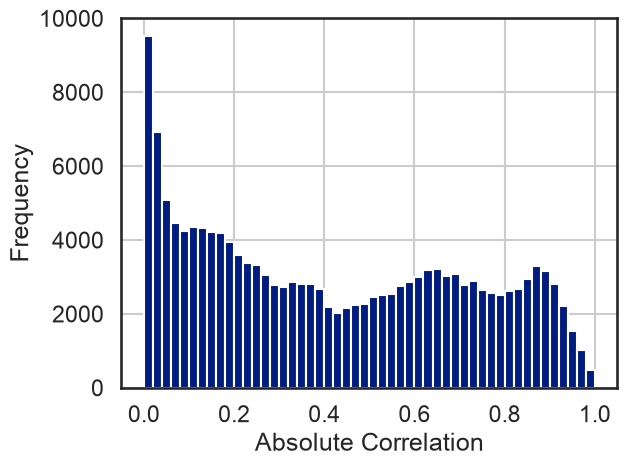

In [11]:
sns.set_context('talk')
sns.set_style('white')
sns.set_palette('dark')

ax = corr_values.abs_correlation.hist(bins=50)

ax.set(xlabel='Absolute Correlation', ylabel='Frequency');

In [12]:
# The most highly correlated values
corr_values.sort_values('correlation', ascending=False).query('abs_correlation>0.8')

,feature1,feature2,correlation,abs_correlation
304047,fBodyBodyGyroJerkMag-mean(),fBodyBodyGyroJerkMag-sma(),1.000000,1.000000
115223,tBodyAccMag-sma(),tGravityAccMag-sma(),1.000000,1.000000
127017,tBodyAccJerkMag-mean(),tBodyAccJerkMag-sma(),1.000000,1.000000
119711,tGravityAccMag-mean(),tGravityAccMag-sma(),1.000000,1.000000
115785,tBodyAccMag-energy(),tGravityAccMag-energy(),1.000000,1.000000
...,...,...,...,...
23560,tGravityAcc-mean()-Y,"angle(Y,gravityMean)",-0.993425,0.993425
42151,"tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4",-0.994267,0.994267
41589,"tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3",-0.994628,0.994628
24122,tGravityAcc-mean()-Z,"angle(Z,gravityMean)",-0.994764,0.994764


### Выводы к вопросу 2

Анализ показал, что большинство признаков имеют слабую корреляцию, однако обнаружены пары с сильной положительной и отрицательной взаимосвязью. Это свидетельствует о наличии признаков, содержащих схожую информацию, что может указывать на мультиколлинеарность в наборе данных

## Вопрос 3. Разделение данных на обучающую и тестовую выборки

На данном этапе выполняется разделение исходного набора данных на обучающую и тестовую выборки с использованием метода `StratifiedShuffleSplit`, который позволяет сохранить пропорциональное распределение классов в обеих выборках.

После разделения проводится сравнение распределения классов в обучающем и тестовом наборах для проверки их сбалансированности.

In [13]:
# Get the split indexes
strat_shuf_split = StratifiedShuffleSplit(n_splits=1,
                                          test_size=0.3,
                                          random_state=42)

train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data.Activity))

# Create the dataframes
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'Activity']

X_test  = data.loc[test_idx, feature_cols]
y_test  = data.loc[test_idx, 'Activity']

In [14]:
y_train.value_counts(normalize=True)

Activity
0    0.188792
2    0.185046
1    0.172562
3    0.167152
5    0.149951
4    0.136496
Name: proportion, dtype: float64

In [15]:
y_test.value_counts(normalize=True)

Activity
0    0.188673
2    0.185113
1    0.172492
3    0.167314
5    0.149838
4    0.136570
Name: proportion, dtype: float64

### Выводы к вопросу 3

Разделение 70 % / 30 % через `StratifiedShuffleSplit` (обучающая — 7 209 объектов, тестовая — 3 090). **Стратификация** сохраняет долю каждого класса в обеих частях; `random_state=42` делает разбиение воспроизводимым.

**Сравнение долей:** например, класс 0 — 0.1888 в train и 0.1887 в test, класс 4 — 0.1365 и 0.1366. Различия в 4-м знаке, то есть пропорции классов практически идентичны, и оценка на тесте будет репрезентативной.

Вопрос 4. Построение моделей логистической регрессии

На данном этапе выполняется построение и сохранение трёх моделей логистической регрессии: без регуляризации, с L1- и L2-регуляризацией. Для регуляризованных моделей подбор оптимальных гиперпараметров осуществляется с помощью перекрёстной валидации с учётом особенностей многоклассовой классификации и ограничений используемых алгоритмов.

In [16]:
# Standard logistic regression
lr = LogisticRegression(penalty=None, max_iter=500).fit(X_train, y_train)

In [17]:
# L1 regularized logistic regression
lr_l1 = LogisticRegressionCV(Cs=10, cv=4, penalty='l1', solver='saga', tol=1e-3, max_iter=300, n_jobs=-1, random_state=42).fit(X_train, y_train)

In [18]:
# L2 regularized logistic regression
lr_l2 = LogisticRegressionCV(Cs=10, cv=4, penalty='l2', max_iter=500, n_jobs=-1).fit(X_train, y_train)

### Выводы к вопросу 4

Обучены три модели на всех 561 признаках:

| Модель | Идея | Выбранное C |
|---|---|---|
| `lr` — без регуляризации | минимизируется только log-loss, веса ничем не ограничены | — |
| `lr_l1` — L1 | штраф λ·Σ\|w\| обнуляет часть весов | ≈ 166.8 |
| `lr_l2` — L2 | штраф λ·Σw² уменьшает все веса | ≈ 21.5 |

Вопрос 5. Сравнение коэффициентов моделей

На данном этапе проводится сравнение величин коэффициентов трёх построенных моделей логистической регрессии: без регуляризации, с L1- и L2-регуляризацией. Для каждой модели анализируется влияние регуляризации на значения коэффициентов. При использовании стратегии «один против остальных» коэффициенты каждого класса визуализируются отдельно.

In [19]:
# Combine all the coefficients into a dataframe
coefficients = list()

coeff_labels = ['lr', 'l1', 'l2']
coeff_models = [lr, lr_l1, lr_l2]

for lab,mod in zip(coeff_labels, coeff_models):
    coeffs = mod.coef_
    coeff_label = pd.MultiIndex(levels=[[lab], [0,1,2,3,4,5]],
                                codes=[[0,0,0,0,0,0], [0,1,2,3,4,5]])
    coefficients.append(pd.DataFrame(coeffs.T, columns=coeff_label))

coefficients = pd.concat(coefficients, axis=1)

coefficients.sample(10)

lr                                                         \
             0          1          2          3          4          5   
367 -18.305016 -15.311331 -29.973905  30.194798  19.282633  14.112822   
177  -0.037533   1.745675   6.228185  -6.526165   3.661601  -5.071762   
506  10.815499 -16.402886  20.491761  -6.435230 -10.115443   1.646298   
154  -6.381669 -11.968146  -3.515422  -0.365701  22.084985   0.145954   
155   5.185925  -1.991088  16.359555  -0.878226 -10.407502  -8.268664   
260 -13.437303 -29.628610 -13.971902  27.207861  13.430941  16.399014   
307  -0.229560   0.360675   4.234601 -12.057873   9.535544  -1.843388   
168  -6.484858 -13.257090   5.888210  10.566430   5.297624  -2.010316   
466   0.840860   3.666458   5.293230   0.582448 -10.251635  -0.131361   
542  -3.197559 -10.828126   9.248886  10.291206  -2.304213  -3.210194   

           l1                                                          l2  \
            0         1         2         3         4         5         0   
367 -0.037538 -0.037899 -0.220016  0.892513 -0.000829 -0.000779 -0.158397   
177 -0.034513 -0.005672  0.082393 -0.010172  0.034919 -0.027820 -0.117915   
506  0.082226 -0.199386  0.249591 -0.057586 -0.024976  0.004763  0.287903   
154 -0.021334 -0.074535 -0.054325 -0.000414  0.211459 -0.030452 -0.086571   
155 -0.018293 -0.083804  0.506945  0.034247 -0.058459 -0.044163 -0.098112   
260 -0.075681 -0.131180  0.070387  0.179203 -0.000001  0.001595 -0.025272   
307 -0.019878 -0.007125  0.039803 -0.148960  0.198023  0.003652 -0.103011   
168 -0.044195 -0.065743  0.062715  0.065277  0.056026 -0.082353 -0.155068   
466 -0.037043  0.003885  0.024848 -0.000782 -0.055016  0.041791 -0.116820   
542 -0.024891 -0.121552  0.260158  0.117947 -0.004335 -0.071311 -0.097070   

                                                       
            1         2         3         4         5  
367  0.022836 -0.762888  0.848885  0.061848 -0.012284  
177 -0.026792  0.214379 -0.120677  0.134386 -0.083382  
506 -1.206360  1.250841 -0.250475 -0.127698  0.045789  
154 -0.301965 -0.063388  0.073223  0.560952 -0.182251  
155 -0.563766  1.010125  0.102783 -0.253966 -0.197064  
260 -0.618225  0.091253  0.592194 -0.065301  0.025352  
307 -0.051738  0.157060 -0.447792  0.391402  0.054078  
168 -0.668966  0.615786  0.453507  0.188109 -0.433368  
466  0.026758  0.125658 -0.021149 -0.181017  0.166570  
542 -0.644105  0.741209  0.335811 -0.127237 -0.208609

In [20]:
print('Лучшее C (L1):', lr_l1.C_)
print('Лучшее C (L2):', lr_l2.C_)
for lab, mod in zip(coeff_labels, coeff_models):
    print(f'{lab}: среднее |коэф.| = {np.abs(mod.coef_).mean():.3f}, '
          f'нулевых коэффициентов = {(mod.coef_ == 0).sum()} из {mod.coef_.size}')

Лучшее C (L1): [166.81005372 166.81005372 166.81005372 166.81005372 166.81005372
 166.81005372]
Лучшее C (L2): [21.5443469 21.5443469 21.5443469 21.5443469 21.5443469 21.5443469]
lr: среднее |коэф.| = 8.830, нулевых коэффициентов = 0 из 3366
l1: среднее |коэф.| = 0.172, нулевых коэффициентов = 4 из 3366
l2: среднее |коэф.| = 0.385, нулевых коэффициентов = 0 из 3366


Подготовлено шесть отдельных графиков для каждого из многоклассовых коэффициентов.

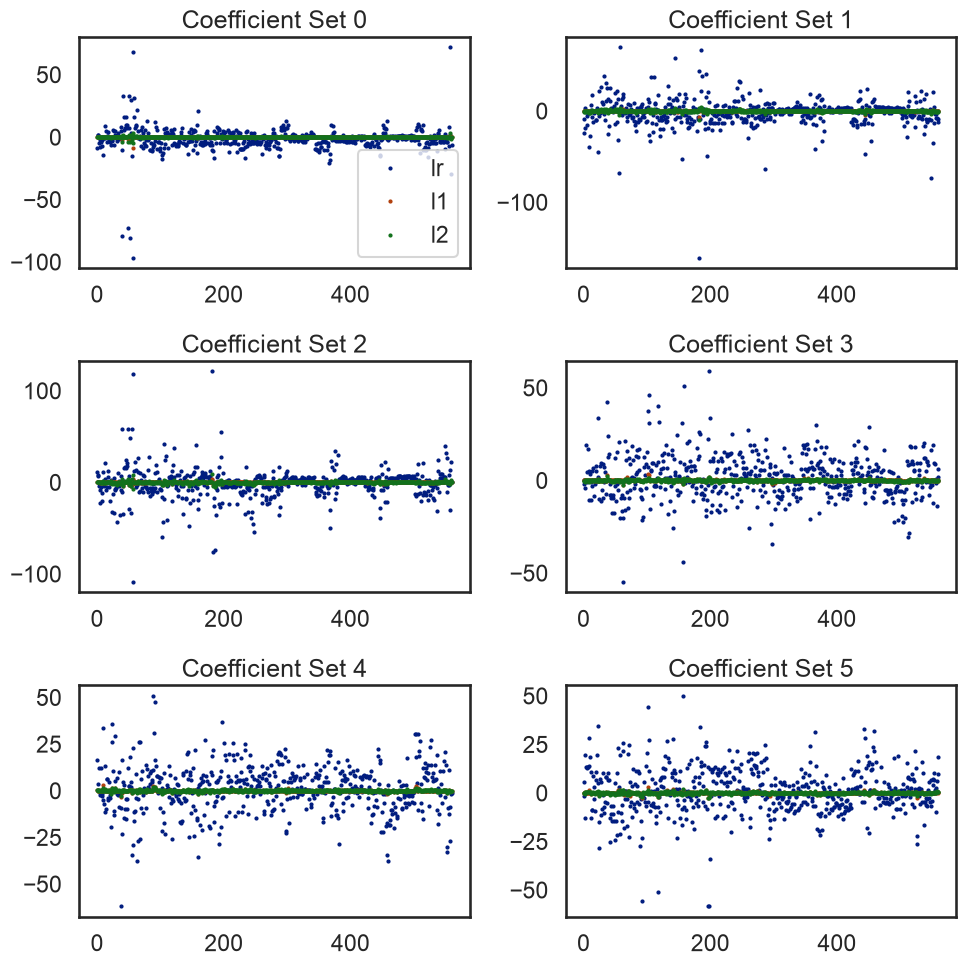

In [21]:
fig, axList = plt.subplots(nrows=3, ncols=2)
axList = axList.flatten()
fig.set_size_inches(10,10)

for ax in enumerate(axList):
    loc = ax[0]
    ax = ax[1]

    coef_set = coefficients.xs(loc, level=1, axis=1)
    coef_set.plot(marker='o', ls='', ms=2.0, ax=ax, legend=False)

    if ax is axList[0]:
        ax.legend(loc=4)

    ax.set(title='Coefficient Set '+str(loc))

plt.tight_layout()

### Выводы к вопросу 5

Каждая модель хранит `coef_` формы (6, 561) — по одному набору коэффициентов на класс (в «один против остальных» / softmax-постановке). Поэтому нарисовано 6 графиков: по оси X — номер признака, по Y — значение коэффициента, цвета — модели.

**Что видно:**

* Модель без регуляризации (`lr`) имеет огромный разброс коэффициентов (среднее |w| ≈ 8.8, значения до десятков) — из-за коррелированных признаков веса «компенсируют» друг друга.
* L2 сжимает все коэффициенты (среднее |w| ≈ 0.39), L1 — ещё сильнее (≈ 0.17) и обнуляет часть из них.
* Нулевых коэффициентов у L1 немного (4 из 3366): кросс-валидация выбрала большое C (слабый штраф). При меньшем C отбор признаков был бы заметнее.
* Наборы коэффициентов разных классов отличаются: каждый класс опирается на свои признаки.

Вопрос 6. Получение предсказаний моделей

На данном этапе для каждой модели логистической регрессии определяются и сохраняются предсказанные классы активности, а также вероятности принадлежности объектов к предсказанным классам.

In [22]:
# Predict the class and the probability for each
y_pred = list()
y_prob = list()

coeff_labels = ['lr', 'l1', 'l2']
coeff_models = [lr, lr_l1, lr_l2]

for lab,mod in zip(coeff_labels, coeff_models):
    y_pred.append(pd.Series(mod.predict(X_test), name=lab))
    y_prob.append(pd.Series(mod.predict_proba(X_test).max(axis=1), name=lab))

y_pred = pd.concat(y_pred, axis=1)
y_prob = pd.concat(y_prob, axis=1)

y_pred.head()

,lr,l1,l2
0,3,3,3
1,5,5,5
2,3,3,3
3,1,1,1
4,0,0,0


In [23]:
y_prob.head()

,lr,l1,l2
0,1.0,0.999999,1.000000
1,1.0,0.999855,0.999991
2,1.0,0.999596,0.999919
3,1.0,0.998574,0.999943
4,1.0,0.998898,0.999949


### Выводы к вопросу 6

* `predict(X_test)` возвращает **метку класса** для каждого тестового объекта; результаты сохранены в `y_pred` (по столбцу на модель: lr, l1, l2).
* `predict_proba(X_test)` возвращает вероятности всех 6 классов; `.max(axis=1)` берёт вероятность **выбранного** (наибольшего) класса — она сохранена в `y_prob`.
* У всех моделей эти вероятности почти равны 1 (≈ 0.998–1.000): модель очень уверена в своих ответах, то есть классы хорошо линейно разделимы. Небольшие значения вероятности указывали бы на «сомнительные» объекты вблизи границы классов.

Вопрос 7. Оценка качества моделей

На данном этапе проводится оценка качества каждой модели логистической регрессии с использованием следующих метрик: accuracy, precision, recall, F1-score и матрицы ошибок (confusion matrix). Для получения единого значения метрик в задаче многоклассовой классификации применяется агрегирование показателей по всем классам.

In [24]:
metrics = list()
cm = dict()

for lab in coeff_labels:

    # Preciision, recall, f-score from the multi-class support function
    precision, recall, fscore, _ = score(y_test, y_pred[lab], average='weighted')

    # The usual way to calculate accuracy
    accuracy = accuracy_score(y_test, y_pred[lab])

    # ROC-AUC scores can be calculated by binarizing the data
    auc = roc_auc_score(label_binarize(y_test, classes=[0,1,2,3,4,5]),
              label_binarize(y_pred[lab], classes=[0,1,2,3,4,5]),
              average='weighted')

    # Last, the confusion matrix
    cm[lab] = confusion_matrix(y_test, y_pred[lab])

    metrics.append(pd.Series({'precision':precision, 'recall':recall,
                              'fscore':fscore, 'accuracy':accuracy,
                              'auc':auc},
                             name=lab))

metrics = pd.concat(metrics, axis=1)

In [25]:
metrics

,lr,l1,l2
precision,0.980945,0.983810,0.985766
recall,0.980906,0.983819,0.985761
fscore,0.980914,0.983811,0.985761
accuracy,0.980906,0.983819,0.985761
auc,0.988448,0.990159,0.991336


### Выводы к вопросу 7

Для каждой модели посчитаны precision, recall, F-score, accuracy и ROC-AUC; матрицы путаницы сохранены в словаре `cm`.

| Метрика | `lr` | `l1` | `l2` |
|---|---|---|---|
| precision | 0.9809 | 0.9838 | 0.9858 |
| recall | 0.9809 | 0.9838 | 0.9858 |
| fscore | 0.9809 | 0.9838 | 0.9858 |
| accuracy | 0.9809 | 0.9838 | 0.9858 |
| auc | 0.9884 | 0.9902 | 0.9913 |

* `weighted` (использовано) — среднее по классам с весами, равными числу объектов класса; подходит, когда классы немного несбалансированы.
* `macro` — простое среднее: все классы одинаково важны. 
* `micro` — глобальный подсчёт TP/FP/FN; для многоклассовой задачи равен accuracy.

Поэтому recall (weighted) совпадает с accuracy — это не случайность. Лучшая модель — **L2**.

Вопрос 8. Визуализация матриц ошибок

На данном этапе строятся и визуализируются матрицы ошибок для каждой модели логистической регрессии с целью анализа правильных и ошибочных классификаций по каждому виду активности.

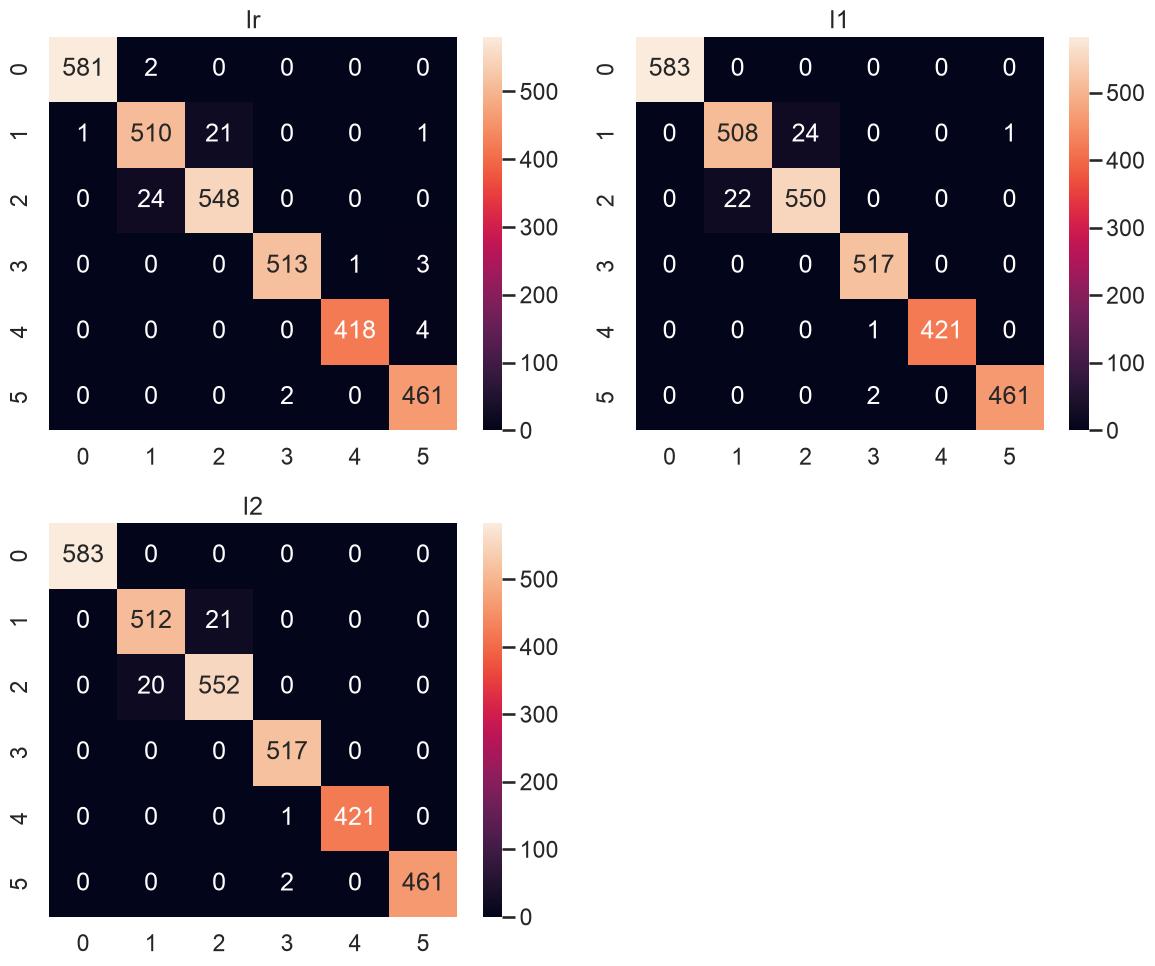

In [26]:
fig, axList = plt.subplots(nrows=2, ncols=2)
axList = axList.flatten()
fig.set_size_inches(12, 10)

axList[-1].axis('off')

for ax,lab in zip(axList[:-1], coeff_labels):
    sns.heatmap(cm[lab], ax=ax, annot=True, fmt='d');
    ax.set(title=lab);

plt.tight_layout()

In [27]:
print('Классы:', dict(enumerate(le.classes_)))
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred['l2'], target_names=le.classes_))

Классы: {0: 'LAYING', 1: 'SITTING', 2: 'STANDING', 3: 'WALKING', 4: 'WALKING_DOWNSTAIRS', 5: 'WALKING_UPSTAIRS'}
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       583
           SITTING       0.96      0.96      0.96       533
          STANDING       0.96      0.97      0.96       572
           WALKING       0.99      1.00      1.00       517
WALKING_DOWNSTAIRS       1.00      1.00      1.00       422
  WALKING_UPSTAIRS       1.00      1.00      1.00       463

          accuracy                           0.99      3090
         macro avg       0.99      0.99      0.99      3090
      weighted avg       0.99      0.99      0.99      3090



### Выводы к вопросу 8

Матрица путаницы: строка — реальный класс, столбец — предсказанный, **диагональ** — верные ответы, остальное — ошибки. Три тепловые карты (lr, l1, l2) выглядят похоже: диагональ очень яркая.

* Почти все ошибки — пара **SITTING ↔ STANDING** (классы 1 и 2): в обеих позах человек неподвижен, сигналы датчиков схожи. Это подтверждает отчёт по классам: у SITTING и STANDING precision/recall ≈ 0.96, у остальных ≈ 1.00.
* LAYING, WALKING, WALKING_DOWNSTAIRS и WALKING_UPSTAIRS распознаются практически идеально.
* Между моделями различие в количестве ошибок небольшое: L2 ошибается реже всего.

### Общие выводы

* **Точность (accuracy)** на тесте: чистая логистическая регрессия — 98.09 %, L1 — 98.38 %, L2 — 98.58 %. Регуляризация немного улучшает обобщающую способность, лучшая модель — **L2**.
* Без регуляризации коэффициенты огромные (среднее |w| ≈ 8.8) из-за коррелированных признаков; L2 уменьшает их до ≈ 0.39, L1 — до ≈ 0.17.
* Вероятности предсказанного класса почти равны 1 — данные хорошо линейно разделимы.